# Heart Disease Dataset Analysis

**Course:** Advance Programming Lab-I (Python)  
**Dataset:** Cleveland heart disease data

The project explores the patient data and compares two classification models. The EDA uses the original diagnosis labels. In the ML section, labels 1 to 4 are combined into one class to predict whether disease is present in the data.

## Assignment coverage

Each numbered task is listed here once. The notebook sections below use the task names as headings without repeating the numbers.

1. Data collection/import using Pandas
2. Data cleaning and preprocessing
3. Handling missing values
4. Removing duplicate records
5. Detecting and handling outliers
6. Descriptive statistics
7. Univariate analysis
8. Bivariate analysis
9. Multivariate analysis
10. Correlation analysis
11. Data visualization using Matplotlib and Seaborn
12. Identification of important patterns and trends
13. Interpretation of findings
14. Final EDA report/dashboard

## Data collection/import using Pandas

The CSV file is included with this notebook, so it can be read from the project folder.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

sns.set_theme(style="whitegrid")
Path("graphs").mkdir(exist_ok=True)
df = pd.read_csv("heart.csv")

print("Rows and columns:", df.shape)
display(df.head())

Rows and columns: (303, 14)


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,num
0,63,1,1,145,233,1,2,150,0,2.3,3,0.0,6.0,0
1,67,1,4,160,286,0,2,108,1,1.5,2,3.0,3.0,2
2,67,1,4,120,229,0,2,129,1,2.6,2,2.0,7.0,1
3,37,1,3,130,250,0,0,187,0,3.5,3,0.0,3.0,0
4,41,0,2,130,204,0,2,172,0,1.4,1,0.0,3.0,0


## Dataset overview

`num` is the diagnosis column. A value of 0 means no disease was recorded; values 1 to 4 are disease categories.

In [2]:
print("Column names:")
print(df.columns.tolist())

print("\nData types and non-empty values:")
df.info()

print("\nMissing values:")
display(df.isna().sum().to_frame("missing"))

print("Duplicate rows:", df.duplicated().sum())
print("\nDiagnosis counts:")
display(df["num"].value_counts().sort_index().to_frame("records"))

Column names:
['age', 'sex', 'cp', 'trestbps', 'chol', 'fbs', 'restecg', 'thalach', 'exang', 'oldpeak', 'slope', 'ca', 'thal', 'num']

Data types and non-empty values:
<class 'pandas.DataFrame'>
RangeIndex: 303 entries, 0 to 302
Data columns (total 14 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       303 non-null    int64  
 1   sex       303 non-null    int64  
 2   cp        303 non-null    int64  
 3   trestbps  303 non-null    int64  
 4   chol      303 non-null    int64  
 5   fbs       303 non-null    int64  
 6   restecg   303 non-null    int64  
 7   thalach   303 non-null    int64  
 8   exang     303 non-null    int64  
 9   oldpeak   303 non-null    float64
 10  slope     303 non-null    int64  
 11  ca        299 non-null    float64
 12  thal      301 non-null    float64
 13  num       303 non-null    int64  
dtypes: float64(3), int64(11)
memory usage: 33.3 KB

Missing values:


,missing
age,0
sex,0
cp,0
trestbps,0
chol,0
fbs,0
restecg,0
thalach,0
exang,0
oldpeak,0


Duplicate rows: 0

Diagnosis counts:


,records
num,
0,164
1,55
2,36
3,35
4,13


## Data cleaning and preprocessing

### Removing duplicate records

Duplicate rows are removed in the next cell. Missing values are handled in the following section, and model preprocessing is performed inside the model pipeline.

In [3]:
df_clean = df.drop_duplicates().copy()
print("Rows after removing duplicates:", len(df_clean))

Rows after removing duplicates: 303


## Handling missing values

The data check found missing values in `ca` and `thal`. These are filled with the most common value in each column.

In [4]:
for column in ["ca", "thal"]:
    df_clean[column] = df_clean[column].fillna(df_clean[column].mode()[0])

print("Missing values after cleaning:", int(df_clean.isna().sum().sum()))

Missing values after cleaning: 0


## Descriptive statistics

In [5]:
display(df_clean.describe().T.round(2))

,count,mean,std,min,25%,50%,75%,max
age,303.0,54.44,9.04,29.0,48.0,56.0,61.0,77.0
sex,303.0,0.68,0.47,0.0,0.0,1.0,1.0,1.0
cp,303.0,3.16,0.96,1.0,3.0,3.0,4.0,4.0
trestbps,303.0,131.69,17.60,94.0,120.0,130.0,140.0,200.0
chol,303.0,246.69,51.78,126.0,211.0,241.0,275.0,564.0
fbs,303.0,0.15,0.36,0.0,0.0,0.0,0.0,1.0
restecg,303.0,0.99,0.99,0.0,0.0,1.0,2.0,2.0
thalach,303.0,149.61,22.88,71.0,133.5,153.0,166.0,202.0
exang,303.0,0.33,0.47,0.0,0.0,0.0,1.0,1.0
oldpeak,303.0,1.04,1.16,0.0,0.0,0.8,1.6,6.2


## Univariate analysis

## Data visualization using Matplotlib and Seaborn

### Diagnosis labels

The chart below shows the original five diagnosis labels, before combining them for classification.

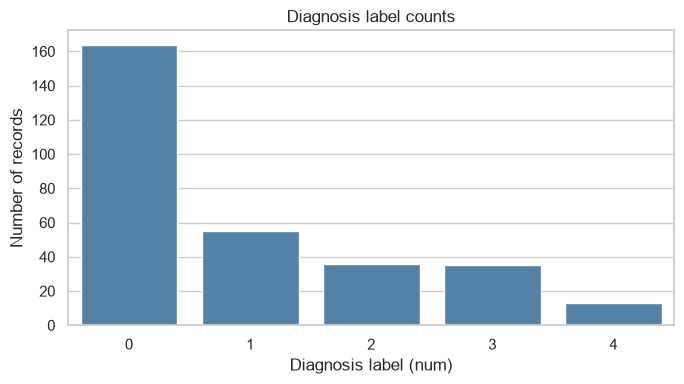

In [6]:
plt.figure(figsize=(7, 4))
sns.countplot(data=df_clean, x="num", color="steelblue")
plt.title("Diagnosis label counts")
plt.xlabel("Diagnosis label (num)")
plt.ylabel("Number of records")
plt.tight_layout()
plt.savefig(Path("graphs") / "diagnosis_counts.png", dpi=200, bbox_inches="tight")
plt.show()

### Univariate analysis: numerical columns

These plots show the distributions of age, resting blood pressure, cholesterol and maximum heart rate.

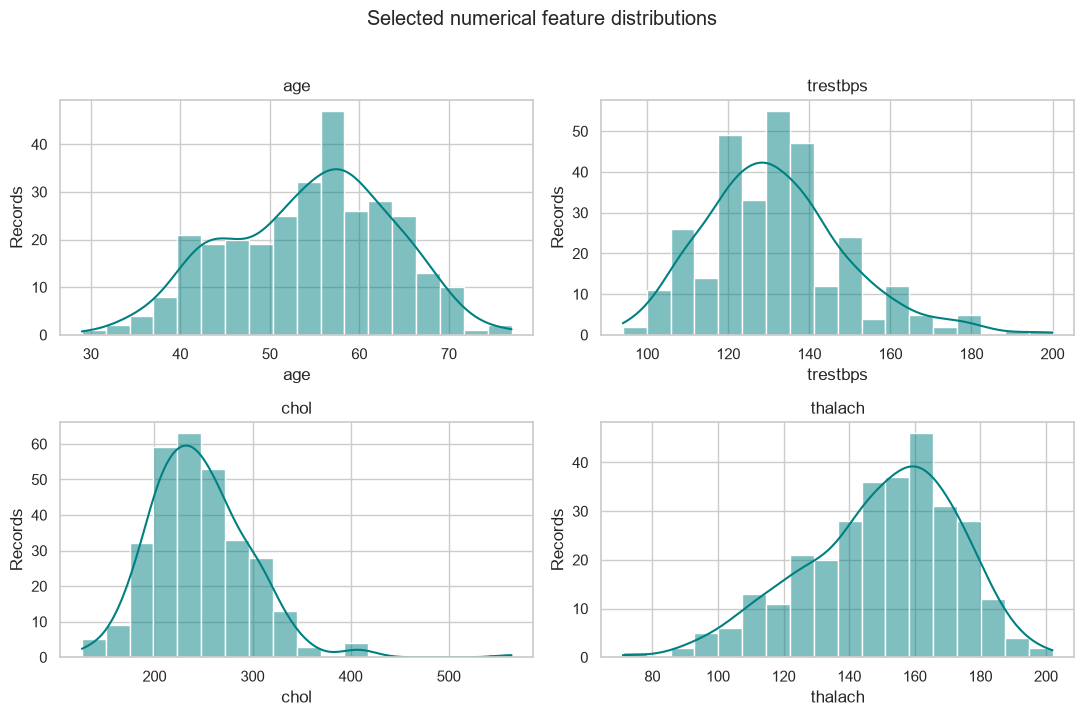

In [7]:
fig, axes = plt.subplots(2, 2, figsize=(11, 7))
for column, ax in zip(["age", "trestbps", "chol", "thalach"], axes.flat):
    sns.histplot(data=df_clean, x=column, bins=18, kde=True, ax=ax, color="teal")
    ax.set_title(column)
    ax.set_ylabel("Records")
fig.suptitle("Selected numerical feature distributions", y=1.02)
plt.tight_layout()
plt.savefig(Path("graphs") / "numerical_distributions.png", dpi=200, bbox_inches="tight")
plt.show()

## Bivariate analysis: chest pain and diagnosis

The feature `cp` uses numeric category codes. The plot compares those codes with the original diagnosis labels.

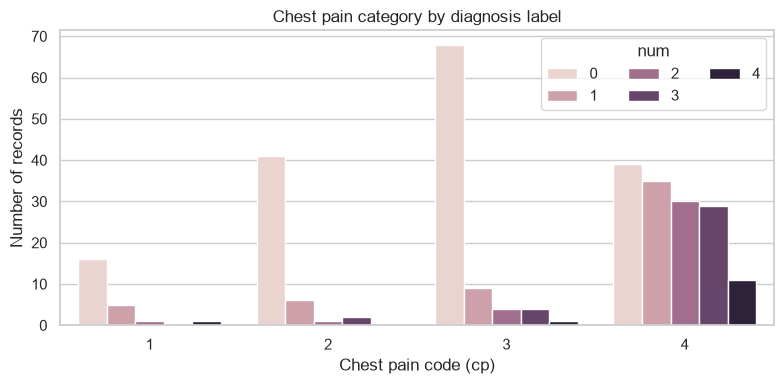

In [8]:
plt.figure(figsize=(8, 4))
sns.countplot(data=df_clean, x="cp", hue="num")
plt.title("Chest pain category by diagnosis label")
plt.xlabel("Chest pain code (cp)")
plt.ylabel("Number of records")
plt.legend(title="num", ncol=3)
plt.tight_layout()
plt.savefig(Path("graphs") / "chest_pain_by_diagnosis.png", dpi=200, bbox_inches="tight")
plt.show()

### Bivariate analysis: measurements by disease status

For this comparison only, labels 1 to 4 are grouped as disease present.

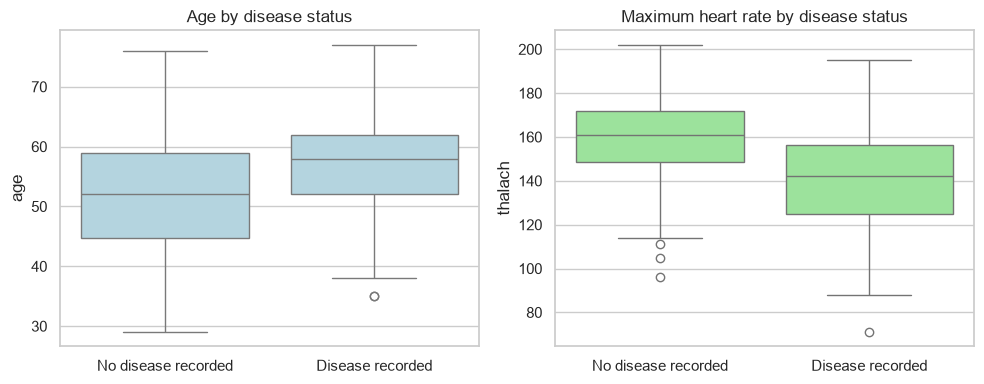

In [9]:
df_clean["disease_present"] = (df_clean["num"] > 0).astype(int)
status_labels = {0: "No disease recorded", 1: "Disease recorded"}
df_clean["status"] = df_clean["disease_present"].map(status_labels)

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
sns.boxplot(data=df_clean, x="status", y="age", ax=axes[0], color="lightblue")
axes[0].set_title("Age by disease status")
axes[0].set_xlabel("")
sns.boxplot(data=df_clean, x="status", y="thalach", ax=axes[1], color="lightgreen")
axes[1].set_title("Maximum heart rate by disease status")
axes[1].set_xlabel("")
plt.tight_layout()
plt.savefig(Path("graphs") / "measurements_by_status.png", dpi=200, bbox_inches="tight")
plt.show()

### Bivariate analysis: age groups and disease rate

### Identification of important patterns and trends

Age is grouped into ten-year bands, and the share of records with `num > 0` is calculated for each band. The chart shows how the rate differs across age groups in this sample. Rates for groups with few records should be interpreted carefully.

,records,disease_rate
age_group,,
20-29,1,0.0
30-39,14,28.6
40-49,72,30.6
50-59,125,48.0
60-69,81,60.5
70-79,10,40.0


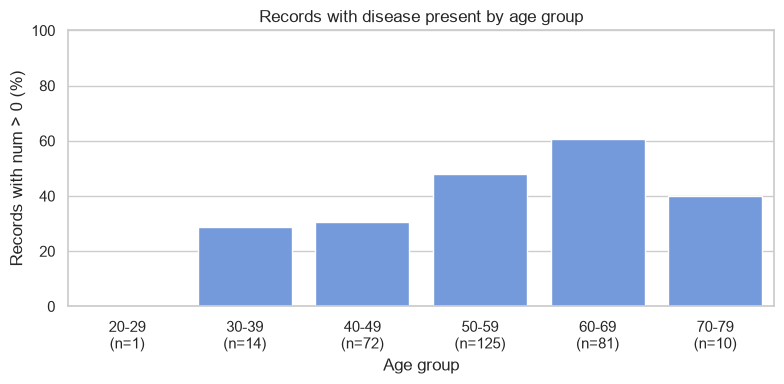

In [10]:
age_bins = [20, 30, 40, 50, 60, 70, 80]
age_labels = ["20-29", "30-39", "40-49", "50-59", "60-69", "70-79"]
df_clean["age_group"] = pd.cut(df_clean["age"], bins=age_bins, labels=age_labels, right=False)
age_trend = (df_clean.groupby("age_group", observed=False)["disease_present"]
             .agg(records="count", disease_rate="mean"))
age_trend["disease_rate"] = (age_trend["disease_rate"] * 100).round(1)
display(age_trend)

plt.figure(figsize=(8, 4))
sns.barplot(x=age_trend.index.astype(str), y=age_trend["disease_rate"], color="cornflowerblue")
plt.title("Records with disease present by age group")
plt.xlabel("Age group")
plt.ylabel("Records with num > 0 (%)")
plt.xticks(range(len(age_trend)), [f"{group}\n(n={count})" for group, count in zip(age_trend.index.astype(str), age_trend["records"])])
plt.ylim(0, 100)
plt.tight_layout()
plt.savefig(Path("graphs") / "disease_rate_by_age_group.png", dpi=200, bbox_inches="tight")
plt.show()

## Correlation analysis

This heatmap is a quick view of pairwise correlations. Some columns are category codes, so their correlations should be read carefully.

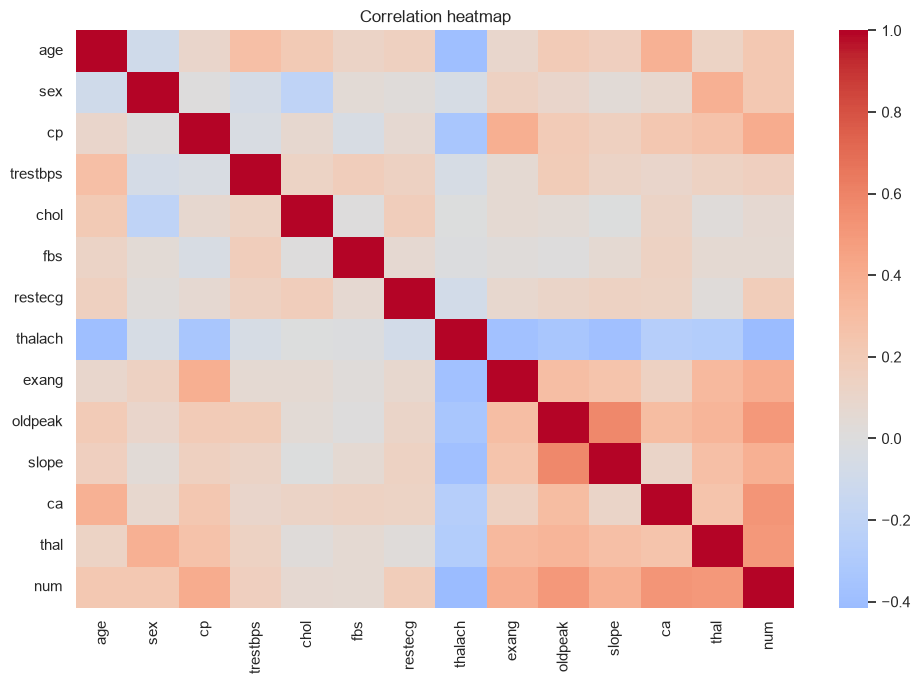

In [11]:
plt.figure(figsize=(10, 7))
sns.heatmap(df_clean.drop(columns=["status", "disease_present"]).corr(numeric_only=True), cmap="coolwarm", center=0, annot=False)
plt.title("Correlation heatmap")
plt.tight_layout()
plt.savefig(Path("graphs") / "correlation_heatmap.png", dpi=200, bbox_inches="tight")
plt.show()

## Multivariate analysis

This plot shows age and maximum heart rate together. Colour shows disease status and marker shape shows sex, so several variables can be compared in one chart.

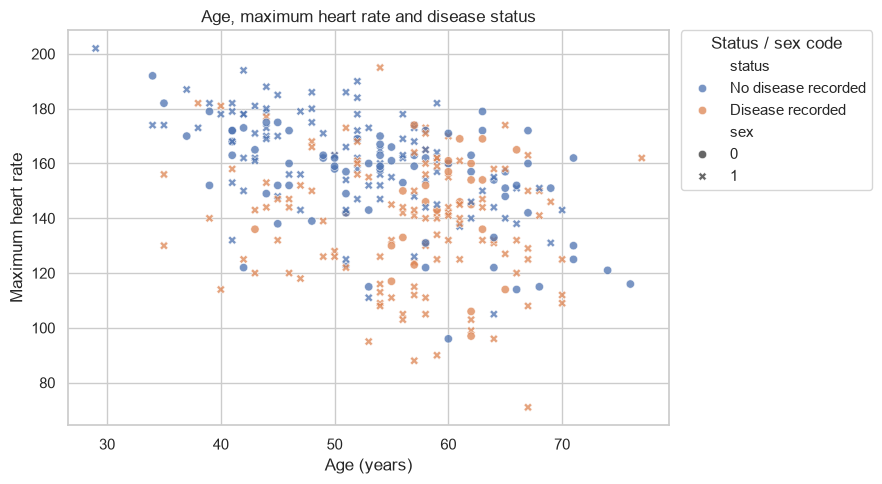

In [12]:
fig, ax = plt.subplots(figsize=(9, 5))
sns.scatterplot(data=df_clean, x="age", y="thalach", hue="status", style="sex", alpha=0.75, ax=ax)
ax.legend(title="Status / sex code", bbox_to_anchor=(1.02, 1), loc="upper left", borderaxespad=0)
plt.title("Age, maximum heart rate and disease status")
plt.xlabel("Age (years)")
plt.ylabel("Maximum heart rate")
plt.tight_layout()
plt.savefig(Path("graphs") / "multivariate_age_heart_rate.png", dpi=200, bbox_inches="tight")
plt.show()

## Detecting and handling outliers

The IQR rule is applied to the continuous measurements to flag possible outliers. A flag does not prove that a value is wrong. The records are retained because the dataset is small and the values may be valid.

In [13]:
continuous_columns = ["age", "trestbps", "chol", "thalach", "oldpeak"]
outlier_rows = []
for column in continuous_columns:
    q1 = df_clean[column].quantile(0.25)
    q3 = df_clean[column].quantile(0.75)
    iqr = q3 - q1
    low = q1 - 1.5 * iqr
    high = q3 + 1.5 * iqr
    count = ((df_clean[column] < low) | (df_clean[column] > high)).sum()
    outlier_rows.append({"column": column, "lower limit": round(low, 2),
                         "upper limit": round(high, 2), "flagged rows": int(count)})

display(pd.DataFrame(outlier_rows).set_index("column"))

,lower limit,upper limit,flagged rows
column,,,
age,28.50,80.50,0
trestbps,90.00,170.00,9
chol,115.00,371.00,5
thalach,84.75,214.75,1
oldpeak,-2.40,4.00,5


## Identification of important patterns and trends

## Interpretation of findings

- The file has 303 records and 13 input features, plus the diagnosis column.
- There are no duplicate rows. Six values are missing: four in `ca` and two in `thal`.
- Diagnosis label 0 appears 164 times. Labels 1 to 4 together appear 139 times.
- The average age is about 52.6 for label 0 and 56.6 for labels 1 to 4 combined. Average maximum heart rate is about 158.4 and 139.3, respectively.
- The age-group chart shows how the share with `num > 0` differs across age bands in this dataset.
- The IQR rule flags some values in blood pressure, cholesterol and other measurements. These values are retained because an IQR flag alone is not enough reason to remove a patient record.

## Interpretation of findings

These are patterns in this dataset. They do not show that one measurement causes heart disease.

## ML classification extension

Logistic Regression and Random Forest are compared. The target is 0 for `num = 0` and 1 for `num > 0`. A stratified split keeps both groups represented in the training and test sets. Imputation, scaling and category encoding are performed inside the pipeline.

In [14]:
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score, ConfusionMatrixDisplay)
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

In [15]:
X = df.drop(columns="num")
y = (df["num"] > 0).astype(int)

categorical_columns = ["sex", "cp", "fbs", "restecg", "exang", "slope", "ca", "thal"]
numerical_columns = [column for column in X.columns if column not in categorical_columns]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

numeric_steps = Pipeline([
    ("fill_missing", SimpleImputer(strategy="median")),
    ("scale", StandardScaler()),
])
category_steps = Pipeline([
    ("fill_missing", SimpleImputer(strategy="most_frequent")),
    ("one_hot", OneHotEncoder(handle_unknown="ignore")),
])
preprocess = ColumnTransformer([
    ("numbers", numeric_steps, numerical_columns),
    ("categories", category_steps, categorical_columns),
])

print("Training records:", len(X_train))
print("Test records:", len(X_test))
print("Training target counts:")
display(y_train.value_counts().sort_index().rename(index={0: "No disease", 1: "Disease present"}).to_frame("records"))

Training records: 242
Test records: 61
Training target counts:


,records
num,
No disease,131
Disease present,111


In [16]:
models = {
    "Logistic Regression": LogisticRegression(
        max_iter=2000, class_weight="balanced", random_state=42
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=300, min_samples_leaf=2, class_weight="balanced",
        random_state=42, n_jobs=-1
    ),
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
model_pipelines = {}
model_predictions = {}
model_probabilities = {}
rows = []

for name, model in models.items():
    pipe = Pipeline([("preprocess", preprocess), ("model", model)])
    cv_result = cross_validate(
        pipe, X_train, y_train, cv=cv,
        scoring=["roc_auc", "f1", "recall"], n_jobs=1
    )
    pipe.fit(X_train, y_train)
    predictions = pipe.predict(X_test)
    probabilities = pipe.predict_proba(X_test)[:, 1]
    model_pipelines[name] = pipe
    model_predictions[name] = predictions
    model_probabilities[name] = probabilities
    rows.append({
        "Model": name,
        "CV ROC-AUC": cv_result["test_roc_auc"].mean(),
        "CV F1": cv_result["test_f1"].mean(),
        "Test accuracy": accuracy_score(y_test, predictions),
        "Test precision": precision_score(y_test, predictions, zero_division=0),
        "Test recall": recall_score(y_test, predictions, zero_division=0),
        "Test F1": f1_score(y_test, predictions, zero_division=0),
        "Test ROC-AUC": roc_auc_score(y_test, probabilities),
    })

comparison = pd.DataFrame(rows).set_index("Model").round(3)
display(comparison)

,CV ROC-AUC,CV F1,Test accuracy,Test precision,Test recall,Test F1,Test ROC-AUC
Model,,,,,,,
Logistic Regression,0.902,0.837,0.869,0.812,0.929,0.867,0.966
Random Forest,0.898,0.783,0.885,0.818,0.964,0.885,0.951


The test set has only 61 records, so a few predictions can change the scores. Cross-validation and test scores are considered together instead of choosing a model from accuracy alone.

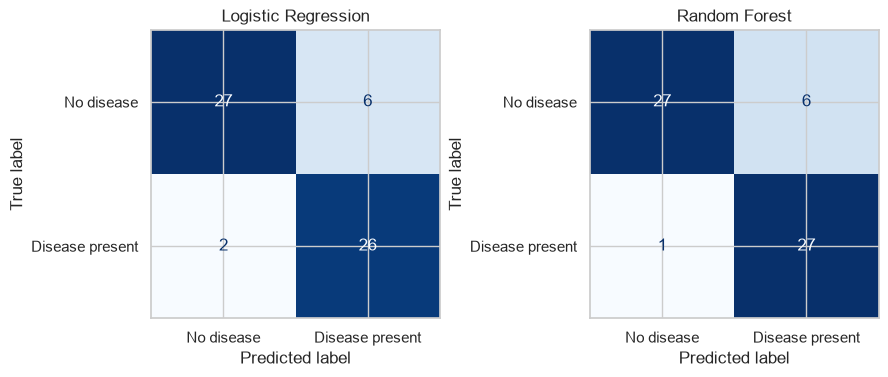

In [17]:
# ML extension: Compare test-set predictions with confusion matrices.
fig, axes = plt.subplots(1, 2, figsize=(9, 4))
for ax, (name, predictions) in zip(axes, model_predictions.items()):
    ConfusionMatrixDisplay.from_predictions(
        y_test, predictions,
        display_labels=["No disease", "Disease present"],
        cmap="Blues", colorbar=False, ax=ax
    )
    ax.set_title(name)
plt.tight_layout()
plt.savefig(Path("graphs") / "model_confusion_matrices.png", dpi=200, bbox_inches="tight")
plt.show()

## Conclusion

For this dataset, Logistic Regression is a reasonable main model because it is easier to explain and its cross-validation scores are competitive with Random Forest. The scores from one split are not enough to say which model will work best on other data.

This is a small dataset used for a class project. The model should not be used to diagnose anyone or guide medical decisions.

## Final EDA report/dashboard

The next cell saves the EDA findings and model comparison in `eda_report.txt`.

In [18]:
positive_count = int(df_clean["disease_present"].sum())
negative_count = int((df_clean["disease_present"] == 0).sum())
means_by_status = df_clean.groupby("status")[["age", "trestbps", "chol", "thalach", "oldpeak"]].mean().round(1)

report_lines = [
    "HEART DISEASE DATA - EDA REPORT",
    "=" * 34,
    "",
    f"Records after duplicate removal: {len(df_clean)}",
    f"Input features: {df.shape[1] - 1}",
    f"Duplicate rows found: {int(df.duplicated().sum())}",
    f"Missing values before cleaning: {int(df.isna().sum().sum())}",
    "Missing values were filled with the most common value in ca and thal.",
    "",
    "ORIGINAL DIAGNOSIS LABELS",
    df_clean["num"].value_counts().sort_index().to_string(),
    "",
    "BINARY GROUPS USED FOR THE CLASSIFICATION EXTENSION",
    f"No disease recorded (num = 0): {negative_count}",
    f"Disease recorded (num > 0): {positive_count}",
    "",
    "AVERAGES BY BINARY GROUP",
    means_by_status.to_string(),
    "",
    "OUTLIER CHECK (IQR RULE)",
    pd.DataFrame(outlier_rows).set_index("column").to_string(),
    "Potential outliers were kept because the IQR rule alone does not establish a data error.",
    "",
    "DISEASE RATE BY AGE GROUP (PERCENT)",
    age_trend.to_string(),
    "",
    "MODEL COMPARISON",
    comparison.to_string(),
    "",
    "INTERPRETATION",
    "Some average measurements differ between the two groups in this dataset. These are descriptive patterns and do not establish cause and effect.",
    "",
    "LIMITATION",
    "This dataset has 303 records. The results are for a class project and are not a medical diagnostic tool."
]
Path("eda_report.txt").write_text("\n".join(report_lines), encoding="utf-8")
print("Saved eda_report.txt")

Saved eda_report.txt
